## Supervised Learning

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

In [2]:
data = load_breast_cancer(as_frame=True)

print(data.data.shape)
print(data.target.shape)

print(data.data.columns.tolist())

(569, 30)
(569,)
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


In [3]:
data.frame.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [4]:
df = pd.read_csv("wdbc.data", header=None)

In [5]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [6]:
print("Dataset shape:", df.shape)


Dataset shape: (569, 32)


In [7]:
columns = [
    "id", "diagnosis",
    "radius_mean", "texture_mean", "perimeter_mean",
    "area_mean", "smoothness_mean", "compactness_mean",
    "concavity_mean", "concave_points_mean", "symmetry_mean",
    "fractal_dimension_mean",
    "radius_se", "texture_se", "perimeter_se", "area_se",
    "smoothness_se", "compactness_se", "concavity_se",
    "concave_points_se", "symmetry_se", "fractal_dimension_se",
    "radius_worst", "texture_worst", "perimeter_worst",
    "area_worst", "smoothness_worst", "compactness_worst",
    "concavity_worst", "concave_points_worst", "symmetry_worst",
    "fractal_dimension_worst"
]

df.columns = columns


In [8]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


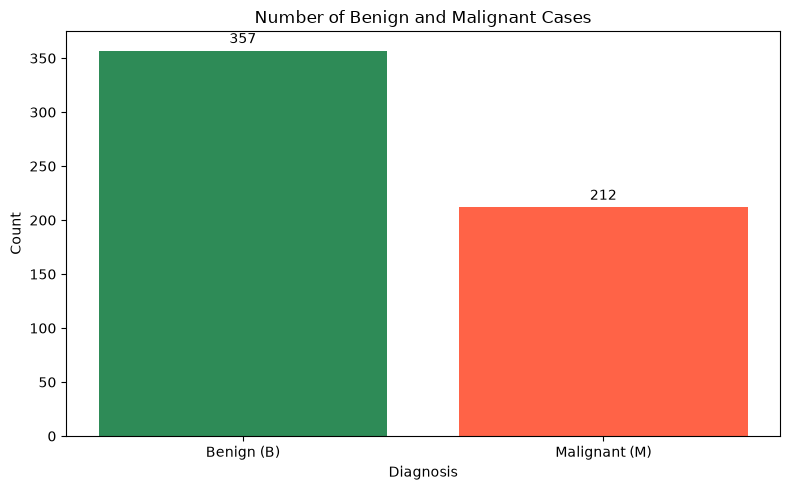

In [9]:
diagnosis_counts = df["diagnosis"].value_counts().reindex(["B", "M"])

plt.figure(figsize=(8, 5))
bars = plt.bar(["Benign (B)", "Malignant (M)"], diagnosis_counts.values, color=["seagreen", "tomato"])
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.title("Number of Benign and Malignant Cases")
plt.bar_label(bars, padding=3)
plt.tight_layout()
plt.show()


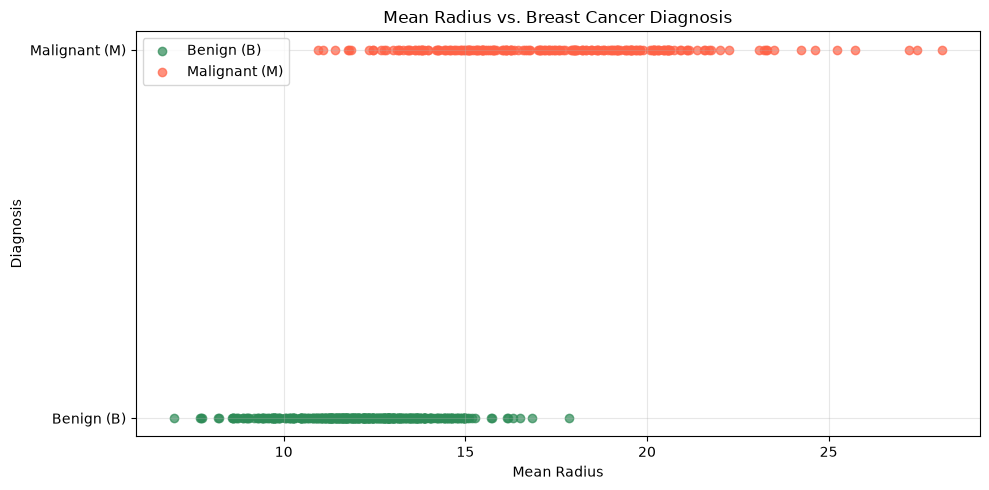

In [10]:

plt.figure(figsize=(10, 5))
benign = df[df["diagnosis"] == "B"]
plt.scatter(benign["radius_mean"], [0] * len(benign), color="seagreen", label="Benign (B)", alpha=0.7)
malignant = df[df["diagnosis"] == "M"]
plt.scatter(malignant["radius_mean"], [1] * len(malignant), color="tomato", label="Malignant (M)", alpha=0.7)
plt.xlabel("Mean Radius")
plt.ylabel("Diagnosis")
plt.title("Mean Radius vs. Breast Cancer Diagnosis")
plt.yticks([0, 1], ["Benign (B)", "Malignant (M)"])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


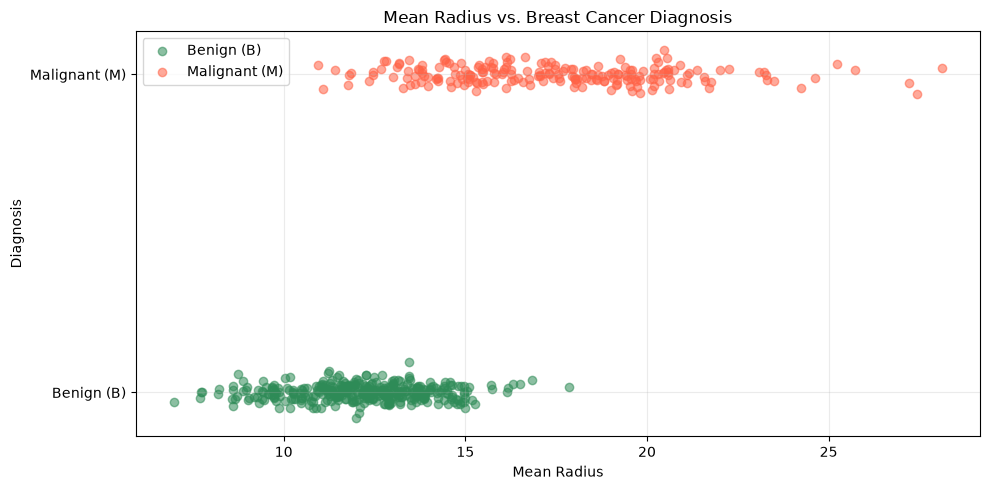

In [11]:
np.random.seed(42)

benign = df[df["diagnosis"] == "B"]
malignant = df[df["diagnosis"] == "M"]
benign_y = np.random.normal(0, 0.025, len(benign))
malignant_y = np.random.normal(1, 0.025, len(malignant))
plt.figure(figsize=(10, 5))
plt.scatter(benign["radius_mean"], benign_y, color="seagreen", alpha=0.55, label="Benign (B)")
plt.scatter( malignant["radius_mean"], malignant_y, color="tomato", alpha=0.55, label="Malignant (M)")
plt.xlabel("Mean Radius")
plt.ylabel("Diagnosis")
plt.yticks([0, 1], ["Benign (B)", "Malignant (M)"])
plt.title("Mean Radius vs. Breast Cancer Diagnosis")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [12]:
#features and target
X = df.drop(columns=["id", "diagnosis"])
y = df["diagnosis"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Diagnosis classes:")
print(y.value_counts())

Features shape: (569, 30)
Target shape: (569,)
Diagnosis classes:
diagnosis
B    357
M    212
Name: count, dtype: int64


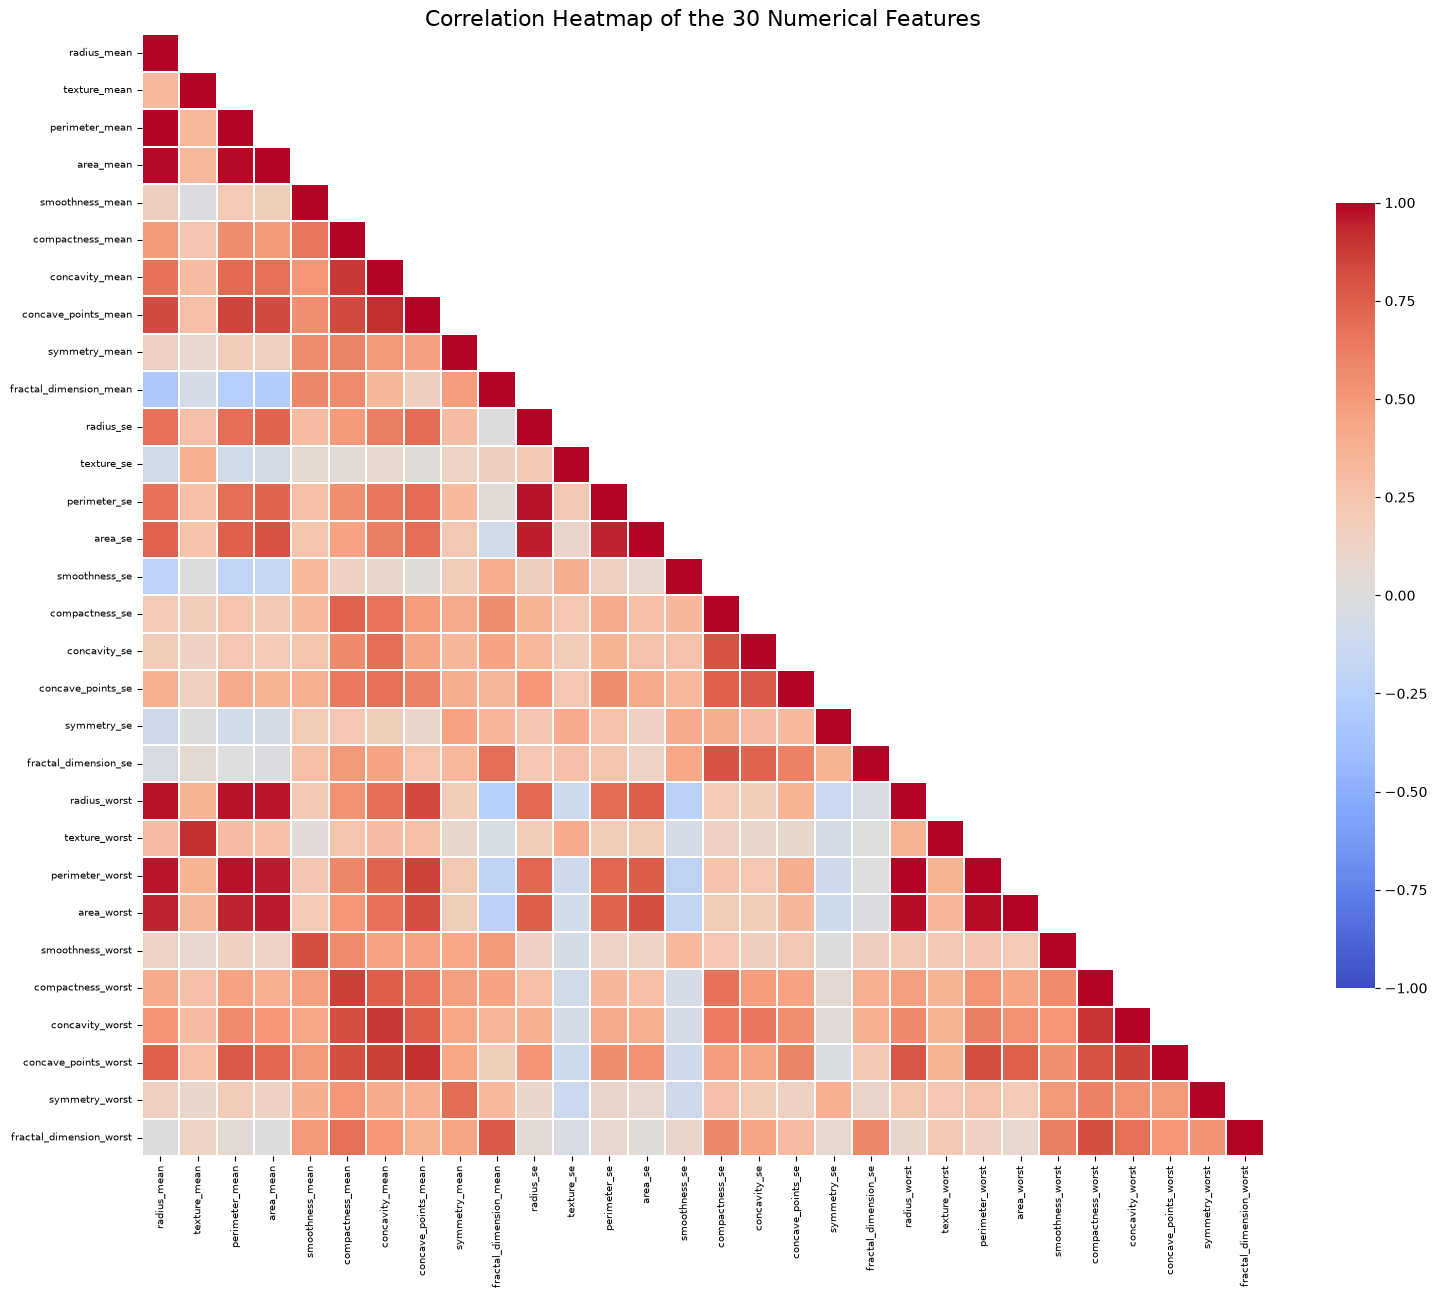

In [13]:
#Calculate the feature-to-feature correlation matrix
corr_matrix = X.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
plt.figure(figsize=(16, 13))
sns.heatmap(corr_matrix, mask=mask, cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True, linewidths=0.1,cbar_kws={"shrink": 0.7})
plt.title("Correlation Heatmap of the 30 Numerical Features", fontsize=16)
plt.xticks(fontsize=7, rotation=90)
plt.yticks(fontsize=7, rotation=0)
plt.tight_layout()
plt.show()

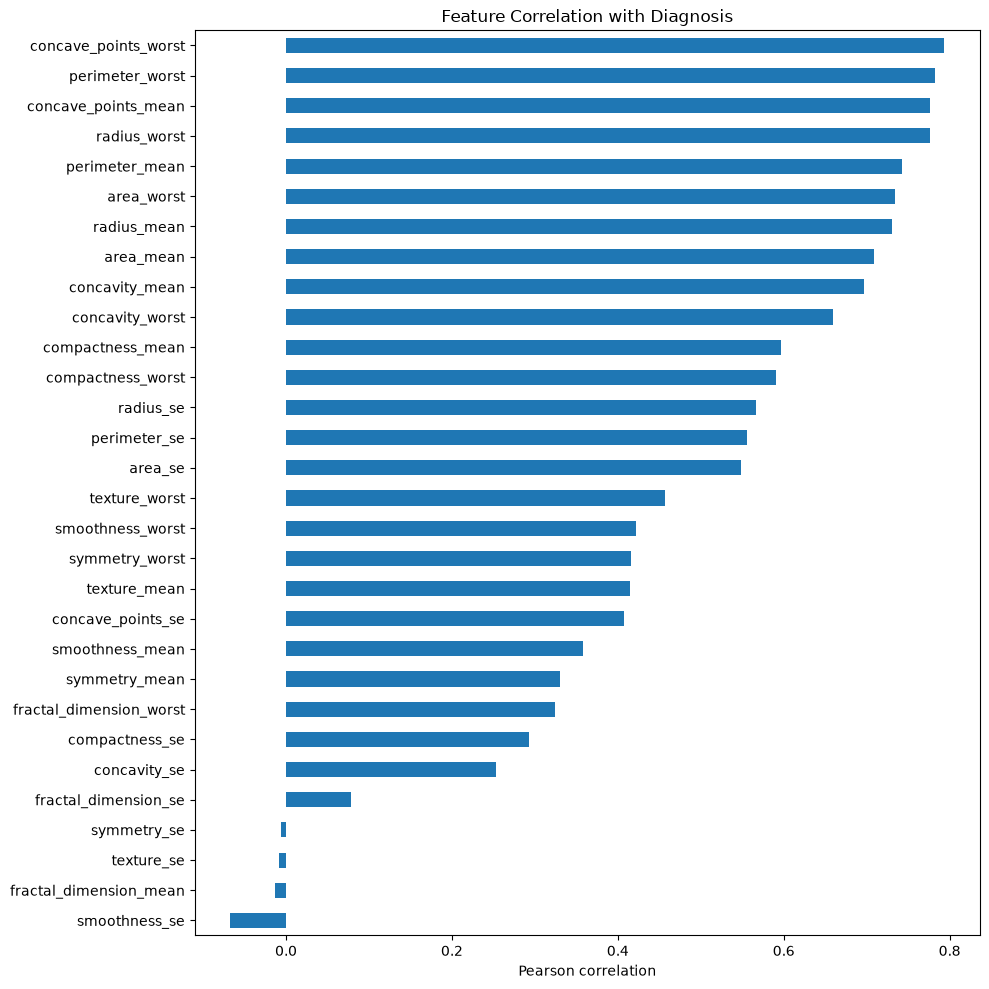

In [14]:
#Encode diagnosis for correlation analysis
y_numeric = y.map({"B": 0, "M": 1})
correlations = X.corrwith(y_numeric).sort_values()
plt.figure(figsize=(10, 10))
correlations.plot(kind="barh")
plt.title("Feature Correlation with Diagnosis")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

In [15]:
#training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining diagnosis counts:")
print(y_train.value_counts())

print("\nTesting diagnosis counts:")
print(y_test.value_counts())

Training features: (455, 30)
Testing features: (114, 30)

Training diagnosis counts:
diagnosis
B    285
M    170
Name: count, dtype: int64

Testing diagnosis counts:
diagnosis
B    72
M    42
Name: count, dtype: int64


In [16]:
#baseline classifier
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
y_pred_baseline = baseline.predict(X_test)
baseline_accuracy = accuracy_score(y_test, y_pred_baseline)

print("Baseline accuracy:", baseline_accuracy)
print("Baseline accuracy (%):", baseline_accuracy * 100)

Baseline accuracy: 0.631578947368421
Baseline accuracy (%): 63.1578947368421


In [17]:
#Standardise features

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [18]:
#Logistic Regression
log_reg = LogisticRegression(max_iter=10000)
log_reg.fit(X_train_scaled, y_train)

y_pred_log = log_reg.predict(X_test_scaled)
log_accuracy = accuracy_score(y_test, y_pred_log)

print("Logistic regression accuracy:", round(log_accuracy, 4))
print("Logistic regression accuracy (%):", round(log_accuracy * 100, 2))

Logistic regression accuracy: 0.9649
Logistic regression accuracy (%): 96.49


In [19]:
#KNN model
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("kNN accuracy:", knn_accuracy)
print("kNN accuracy:", round(knn_accuracy, 4))
print("kNN accuracy (%):", round(knn_accuracy * 100, 2))

kNN accuracy: 0.956140350877193
kNN accuracy: 0.9561
kNN accuracy (%): 95.61


In [20]:
#Compare model performance

results = pd.DataFrame({
    "Model": [
        "Baseline (most frequent)",
        "Logistic Regression",
        "kNN (k=5)"
    ],
    "Test accuracy": [
        baseline_accuracy,
        log_accuracy,
        knn_accuracy
    ]
})

results["Test error"] = 1 - results["Test accuracy"]

print(results.to_string(
    index=False,
    formatters={
        "Test accuracy": "{:.4f}".format,
        "Test error": "{:.4f}".format
    }
))


                   Model Test accuracy Test error
Baseline (most frequent)        0.6316     0.3684
     Logistic Regression        0.9649     0.0351
               kNN (k=5)        0.9561     0.0439


In [21]:
print("Logistic Regression — Confusion Matrix")
print(confusion_matrix(y_test, y_pred_log, labels=["B", "M"]))

print("\nLogistic Regression — Classification Report")
print(classification_report(y_test, y_pred_log, labels=["B", "M"]))

print("\nkNN (k=5) — Confusion Matrix")
print(confusion_matrix(y_test, y_pred_knn, labels=["B", "M"]))

print("\nkNN (k=5) — Classification Report")
print(classification_report(y_test, y_pred_knn, labels=["B", "M"]))

Logistic Regression — Confusion Matrix
[[71  1]
 [ 3 39]]

Logistic Regression — Classification Report
              precision    recall  f1-score   support

           B       0.96      0.99      0.97        72
           M       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114


kNN (k=5) — Confusion Matrix
[[71  1]
 [ 4 38]]

kNN (k=5) — Classification Report
              precision    recall  f1-score   support

           B       0.95      0.99      0.97        72
           M       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



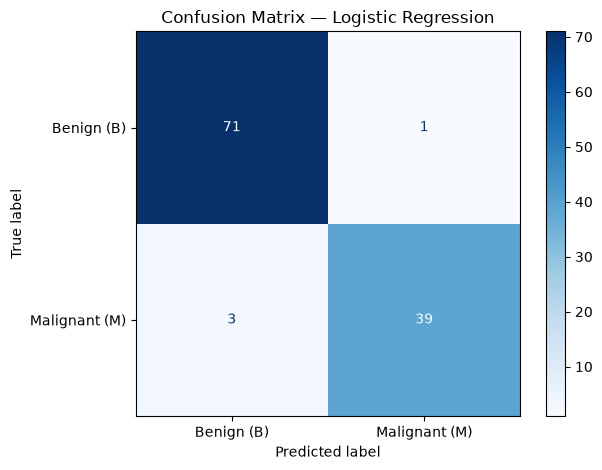

In [22]:
cm = confusion_matrix(y_test, y_pred_log, labels=["B", "M"])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign (B)", "Malignant (M)"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix — Logistic Regression")
plt.tight_layout()
plt.show()

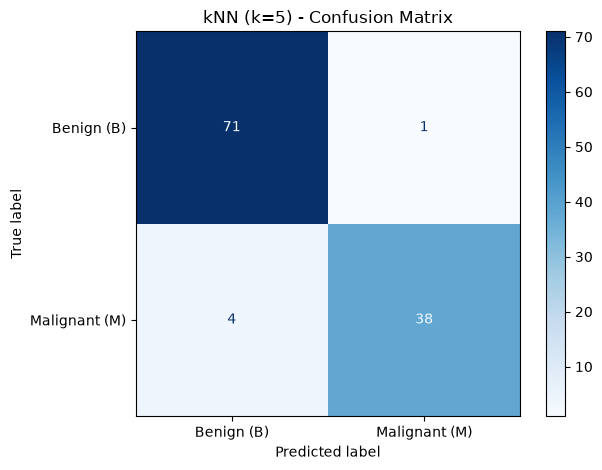

In [23]:
cm_knn = confusion_matrix(y_test, y_pred_knn, labels=["B", "M"])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=["Benign (B)", "Malignant (M)"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("kNN (k=5) - Confusion Matrix")
plt.tight_layout()
plt.show()

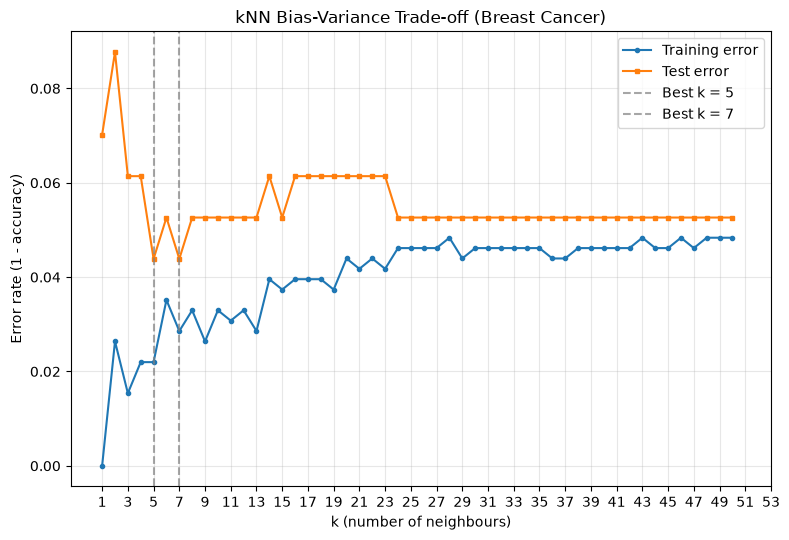

In [24]:
#Bias-variance trade-off
ks = range(1, 51)
train_errors = []
test_errors = []

for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)

    train_predictions = knn.predict(X_train_scaled)
    test_predictions = knn.predict(X_test_scaled)

    train_errors.append(1 - accuracy_score(y_train, train_predictions))
    test_errors.append(1 - accuracy_score(y_test, test_predictions))

train_errors = np.array(train_errors)
test_errors = np.array(test_errors)


min_test_error = np.min(test_errors)

best_ks = [
    k for k, error in zip(ks, test_errors)
    if np.isclose(error, min_test_error)
]



plt.figure(figsize=(8, 5.5))
plt.plot(ks, train_errors, marker="o", markersize=3, label="Training error")
plt.plot(ks, test_errors, marker="s", markersize=3, label="Test error")
for k in best_ks:
    plt.axvline(k, color="grey", linestyle="--", alpha=0.7, label=f"Best k = {k}")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Error rate (1 - accuracy)")
plt.title("kNN Bias-Variance Trade-off (Breast Cancer)")
plt.xticks(range(1, 54, 2))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("bias_variance.png", dpi=150)
plt.show()


In [25]:
#Best k
min_test_error = min(test_errors)

best_k_values = [
    k for k, error in zip(ks, test_errors)
    if error == min_test_error
]

print("Minimum test error:", min_test_error)
print("Best k value(s):", best_k_values)
print("Test accuracy:", 1 - min_test_error)

Minimum test error: 0.04385964912280704
Best k value(s): [5, 7]
Test accuracy: 0.956140350877193


In [26]:
# Print selected k values and their training/test errors
print(f"{'k':>3} | {'train_error':>11} | {'test_error':>10}")
print("-" * 32)

for k, tr, te in zip(ks, train_errors, test_errors):
    if k in (1, 2, 3, 4, 5, 7, 8, 10, 12, 15, 20, 30, 40, 50):
        print(f"{k:>3} | {tr:>11.3f} | {te:>10.3f}")

print("-" * 32)
print(f"Best k values = {best_ks}")
print(f"Minimum test error = {test_errors.min():.3f}")


  k | train_error | test_error
--------------------------------
  1 |       0.000 |      0.070
  2 |       0.026 |      0.088
  3 |       0.015 |      0.061
  4 |       0.022 |      0.061
  5 |       0.022 |      0.044
  7 |       0.029 |      0.044
  8 |       0.033 |      0.053
 10 |       0.033 |      0.053
 12 |       0.033 |      0.053
 15 |       0.037 |      0.053
 20 |       0.044 |      0.061
 30 |       0.046 |      0.053
 40 |       0.046 |      0.053
 50 |       0.048 |      0.053
--------------------------------
Best k values = [5, 7]
Minimum test error = 0.044
